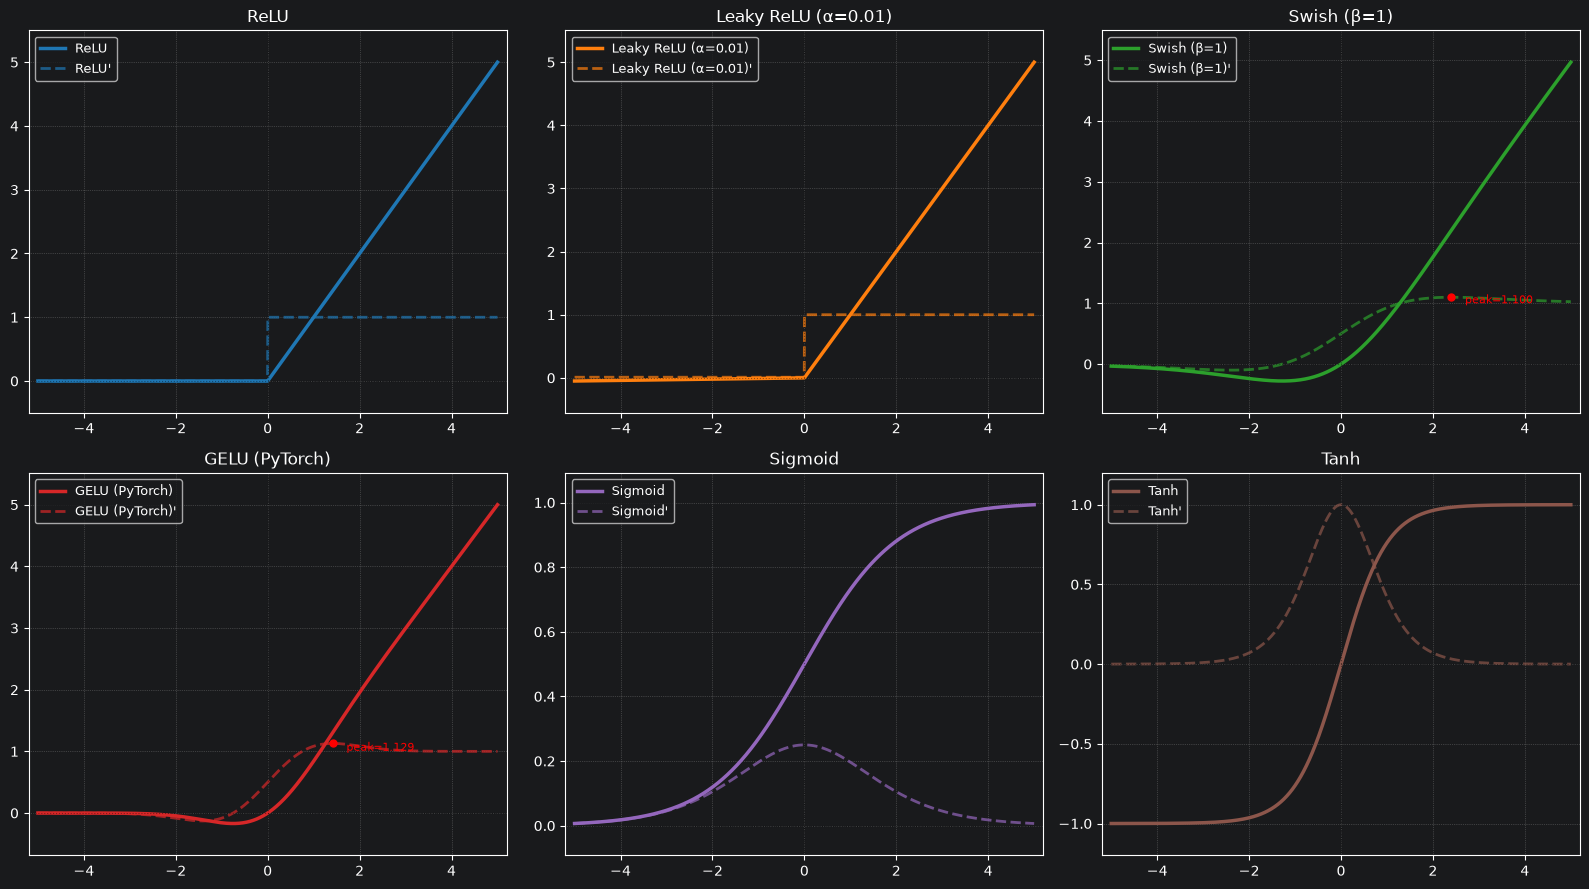


关键数值汇总 (自动缩放后)

ReLU:
  原函数范围: [0.0000, 5.0000]
  导数范围:   [0.0000, 1.0000]
  → 在 x=0 处不可导 (次梯度为 0~1)

Leaky ReLU (α=0.01):
  原函数范围: [-0.0500, 5.0000]
  导数范围:   [0.0100, 1.0000]
  → 负区间梯度 = 0.01, 正区间梯度 = 1

Swish (β=1):
  原函数范围: [-0.2785, 4.9665]
  导数范围:   [-0.0998, 1.0998]
  → 导数峰值: x=2.3987, y=1.0998

GELU (PyTorch):
  原函数范围: [-0.1700, 5.0000]
  导数范围:   [-0.1289, 1.1289]
  → 导数峰值: x=1.4132, y=1.1289

Sigmoid:
  原函数范围: [0.0067, 0.9933]
  导数范围:   [0.0066, 0.2500]

Tanh:
  原函数范围: [-0.9999, 0.9999]
  导数范围:   [0.0002, 1.0000]


In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# 1. 定义激活函数（统一接口）
# ============================================================
def relu(x):
    return torch.relu(x)

def leaky_relu(x, alpha=0.01):
    return torch.where(x >= 0, x, alpha * x)

def swish(x, beta=1.0):
    return x * torch.sigmoid(beta * x)

def gelu(x):
    return nn.GELU()(x)  # PyTorch 近似版本

def sigmoid(x):
    return torch.sigmoid(x)

def tanh(x):
    return torch.tanh(x)

# ============================================================
# 2. 计算原函数和导数的工具函数
# ============================================================
def compute_function_and_derivative(func, x):
    """计算函数值及其导数 (使用自动微分)"""
    x_req = x.clone().detach().requires_grad_(True)
    y = func(x_req)
    dy = torch.autograd.grad(y.sum(), x_req, create_graph=False)[0]
    return y.detach(), dy.detach()

# ============================================================
# 3. 生成数据
# ============================================================
x = torch.linspace(-5, 5, 2000)

# 所有要绘制的函数
funcs = {
    "ReLU": relu,
    "Leaky ReLU (α=0.01)": lambda x: leaky_relu(x, 0.01),
    "Swish (β=1)": swish,
    "GELU (PyTorch)": gelu,
    "Sigmoid": sigmoid,
    "Tanh": tanh,
}

results = {}
for name, func in funcs.items():
    y, dy = compute_function_and_derivative(func, x)
    results[name] = (y, dy)

# ============================================================
# 4. 绘图（自动调整坐标轴范围）
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for idx, (name, (y, dy)) in enumerate(results.items()):
    ax = axes[idx]
    x_np = x.numpy()
    y_np = y.numpy()
    dy_np = dy.numpy()

    # ---- 绘制曲线 ----
    ax.plot(x_np, y_np, label=f'{name}', linewidth=2.5, color=colors[idx % len(colors)])
    ax.plot(x_np, dy_np, label=f"{name}'", linewidth=2, linestyle='--',
            color=colors[idx % len(colors)], alpha=0.7)

    # ---- 关键点标注 ----
    if name == "GELU (PyTorch)":
        peak_idx = torch.argmax(dy)
        ax.plot(x[peak_idx].item(), dy[peak_idx].item(), 'ro', markersize=5)
        ax.text(x[peak_idx].item() + 0.3, dy[peak_idx].item() - 0.12,
                f'peak={dy[peak_idx].item():.3f}', fontsize=8, color='red')
    elif name == "Swish (β=1)":
        peak_idx = torch.argmax(dy)
        ax.plot(x[peak_idx].item(), dy[peak_idx].item(), 'ro', markersize=5)
        ax.text(x[peak_idx].item() + 0.3, dy[peak_idx].item() - 0.1,
                f'peak={dy[peak_idx].item():.3f}', fontsize=8, color='red')

    # ---- 零轴参考线 ----
    ax.axhline(0, color='black', linestyle=':', linewidth=0.8, alpha=0.4)
    ax.axvline(0, color='black', linestyle=':', linewidth=0.8, alpha=0.4)

    # ---- 🎯 核心改进：根据数据自动调整坐标轴范围 ----
    all_y = np.concatenate([y_np, dy_np])
    y_min, y_max = all_y.min(), all_y.max()

    # 增加 10% 的边距，让曲线不贴边
    margin = (y_max - y_min) * 0.1 if y_max > y_min else 0.5
    ax.set_ylim(y_min - margin, y_max + margin)
    ax.set_xlim(-5.2, 5.2)  # x 轴固定，稍微留点边

    # 网格和标签
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper left', fontsize=9)
    ax.set_title(name, fontsize=12)

plt.tight_layout()
plt.savefig('activation_functions_auto_scale.png', dpi=200, bbox_inches='tight')
plt.show()

# ============================================================
# 5. 打印关键数值
# ============================================================
print("\n" + "=" * 65)
print("关键数值汇总 (自动缩放后)")
print("=" * 65)

for name, (y, dy) in results.items():
    print(f"\n{name}:")
    print(f"  原函数范围: [{y.min().item():.4f}, {y.max().item():.4f}]")
    print(f"  导数范围:   [{dy.min().item():.4f}, {dy.max().item():.4f}]")

    if name == "GELU (PyTorch)":
        peak_idx = torch.argmax(dy)
        print(f"  → 导数峰值: x={x[peak_idx].item():.4f}, y={dy[peak_idx].item():.4f}")
    elif name == "Swish (β=1)":
        peak_idx = torch.argmax(dy)
        print(f"  → 导数峰值: x={x[peak_idx].item():.4f}, y={dy[peak_idx].item():.4f}")
    elif name == "ReLU":
        print(f"  → 在 x=0 处不可导 (次梯度为 0~1)")
    elif name == "Leaky ReLU (α=0.01)":
        print(f"  → 负区间梯度 = 0.01, 正区间梯度 = 1")